# Lap time EDA
Target: `lap_delta_s` on clean race laps. Training races only (2023–2025 and 2026 rounds 1–11); test rounds 2026 R12–23 are never loaded. Wet races are dropped with `race_meta.is_wet`.

In [1]:
import logging

import fastf1
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from f1strat.data.cache import CACHE_DIR, enable_cache
from f1strat.data.events import build_events
from f1strat.data.lap_table import build_lap_table
from f1strat.data.long_runs import DRY_COMPOUNDS, practice_long_runs
from f1strat.data.race_meta import build_race_meta, rain_slowdown

enable_cache()
fastf1.Cache.offline_mode(True)
fastf1.set_log_level(logging.ERROR)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.precision", 3)

EDA_DIR = CACHE_DIR.parent / "eda"
FIG_DIR = CACHE_DIR.parents[1] / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SEASONS = (2023, 2024, 2025, 2026)
LAST_2026_TRAIN_ROUND = 11
TABLES = ("laps", "meta", "runs")
COLORS = {"SOFT": "tab:red", "MEDIUM": "goldenrod", "HARD": "dimgray"}

In [2]:
def training_rounds():
    for season in SEASONS:
        rounds = fastf1.get_event_schedule(season, include_testing=False)["RoundNumber"].astype(int)
        for round_number in rounds:
            if season < 2026 or round_number <= LAST_2026_TRAIN_ROUND:
                yield season, round_number


def load_race(season, round_number):
    event = fastf1.get_event(season, round_number)
    session = event.get_session("Race")
    session.load(laps=True, telemetry=False, weather=True, messages=True)
    events = build_events(session.track_status, session.race_control_messages, session.laps, season, round_number)
    table = build_lap_table(session.laps, session.weather_data, season, round_number, event["Location"], events)
    meta = build_race_meta(
        session.laps,
        session.weather_data,
        season=season,
        round_number=round_number,
        event_name=event["EventName"],
        circuit=event["Location"],
        event_format=event["EventFormat"],
        scheduled_laps=session.total_laps,
        rain_slowdown_s=rain_slowdown(table),
    )
    return table, meta, practice_long_runs(season, round_number)


def build_eda_tables():
    races = [load_race(season, round_number) for season, round_number in training_rounds()]
    return {name: pd.concat(parts, ignore_index=True) for name, parts in zip(TABLES, zip(*races))}


paths = {name: EDA_DIR / f"{name}.pkl" for name in TABLES}
if all(path.exists() for path in paths.values()):
    tables = {name: pd.read_pickle(path) for name, path in paths.items()}
else:
    tables = build_eda_tables()
    EDA_DIR.mkdir(parents=True, exist_ok=True)
    for name, table in tables.items():
        table.to_pickle(paths[name])
meta = tables["meta"]
meta.groupby("season").size().rename("races").to_frame().T

season,2023,2024,2025,2026
races,22,24,24,11


In [3]:
dry_races = meta.loc[~meta["is_wet"], ["season", "round"]]
laps = tables["laps"].merge(dry_races)
runs = tables["runs"].infer_objects().merge(dry_races)
STINT_KEY = ["season", "round", "driver", "stint"]
by_stint = laps.groupby(STINT_KEY)
by_driver = laps.groupby(["season", "round", "driver"])
consecutive = by_driver["lap_number"].diff().eq(1)
laps = laps.assign(
    era=np.where(laps["season"] == 2026, "2026", "2023-25"),
    stint_lap=laps["tyre_age"] - by_stint["tyre_age"].transform("min"),
    laps_to_stint_end=by_stint["lap_number"].transform("max") - laps["lap_number"],
    stint_ends_in_pit=by_stint["is_pit_in_lap"].transform("last").eq(True),
    gap_ahead_start_s=by_driver["gap_ahead_s"].shift().where(consecutive),
    later_stint=laps["stint"].fillna(1).gt(1).astype(bool),
)
clean = laps[laps["is_clean_lap"] & laps["tyre_age"].notna()].copy()
print(f"{len(meta)} training races, {meta['is_wet'].sum()} wet, {len(dry_races)} dry")
print(f"{len(laps)} laps, {laps['is_clean_lap'].sum()} clean, {len(clean)} clean with a tyre age")
meta.loc[meta["is_wet"], ["season", "round", "event_name", "has_rainfall", "wet_tyre_laps", "rain_slowdown_s"]]

81 training races, 10 wet, 71 dry
79558 laps, 66277 clean, 66258 clean with a tyre age


,season,round,event_name,has_rainfall,wet_tyre_laps,rain_slowdown_s
5,2023,6,Monaco Grand Prix,True,444,12.008
11,2023,12,Belgian Grand Prix,True,0,2.179
12,2023,13,Dutch Grand Prix,True,328,1.041
30,2024,9,Canadian Grand Prix,True,846,NaN
33,2024,12,British Grand Prix,True,234,1.318
42,2024,21,São Paulo Grand Prix,True,1134,NaN
46,2025,1,Australian Grand Prix,True,750,5.913
57,2025,12,British Grand Prix,True,608,NaN
58,2025,13,Belgian Grand Prix,False,240,0.000
74,2026,5,Canadian Grand Prix,False,14,0.000


## 1. Clean laps and stint lengths

In [4]:
pd.crosstab(clean["season"], clean["compound"], margins=True)

compound,HARD,MEDIUM,SOFT,All
season,,,,
2023,9406,5848,1744,16998
2024,11955,6772,1329,20056
2025,9263,8230,2556,20049
2026,4834,3319,1002,9155
All,35458,24169,6631,66258


In [5]:
laps.groupby(["season", "round"])["is_clean_lap"].mean().groupby("season").describe()[["min", "50%", "max"]]

,min,50%,max
season,,,
2023,0.636,0.815,0.941
2024,0.689,0.874,0.947
2025,0.548,0.855,0.934
2026,0.725,0.793,0.853


In [6]:
clean.groupby(["circuit", "season"]).size().unstack(fill_value=0)

season,2023,2024,2025,2026
circuit,,,,
Austin,880,836,898,0
Baku,784,852,777,0
Barcelona,1198,1192,964,997
Budapest,1124,1227,1275,1218
Imola,0,1153,921,0
Jeddah,790,769,780,0
Las Vegas,602,820,760,0
Lusail,746,650,887,0
Marina Bay,812,1097,1105,0


In [7]:
stints = (
    laps.dropna(subset=["stint", "compound"])
    .groupby(STINT_KEY)
    .agg(era=("era", "first"), compound=("compound", "first"), laps=("lap_number", "size"))
    .reset_index()
)
stops = stints.groupby(["era", "season", "round", "driver"]).size().sub(1).groupby("era").mean().rename("stops_per_driver")
display(stops.to_frame().T)
stints.groupby(["compound", "era"])["laps"].describe(percentiles=[0.1, 0.5, 0.9])[["count", "10%", "50%", "90%", "max"]]

era,2023-25,2026
stops_per_driver,1.745,1.869


count  10%   50%   90%   max
compound era                                   
HARD     2023-25  1374.0  8.0  25.0  42.0  77.0
         2026      240.0  8.9  25.0  37.2  51.0
MEDIUM   2023-25  1371.0  5.0  18.0  31.0  77.0
         2026      224.0  6.0  18.0  29.0  59.0
SOFT     2023-25   582.0  1.0  12.0  24.0  38.0
         2026      150.0  1.0   8.0  19.0  55.0

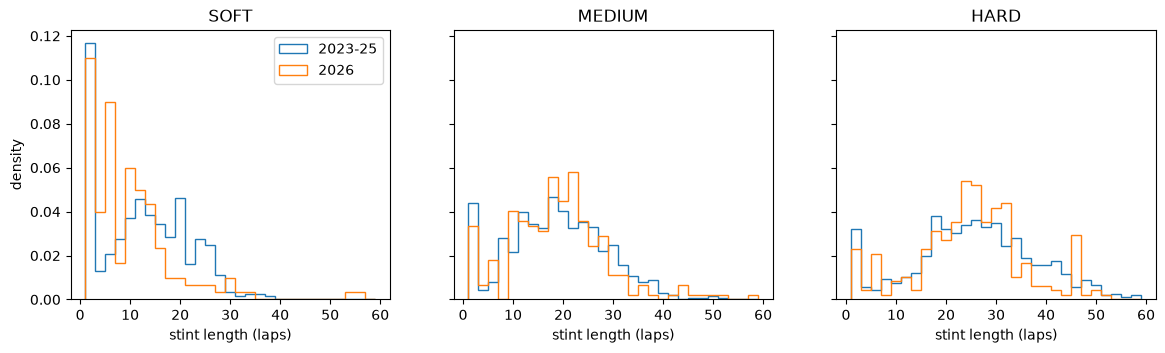

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, compound in zip(axes, DRY_COMPOUNDS):
    for era, group in stints[stints["compound"] == compound].groupby("era"):
        ax.hist(group["laps"], bins=range(1, 60, 2), density=True, histtype="step", label=era)
    ax.set(title=compound, xlabel="stint length (laps)")
axes[0].set_ylabel("density")
axes[0].legend()
fig.savefig(FIG_DIR / "eda_stint_lengths.png", dpi=120, bbox_inches="tight")

**Findings.**
- 81 training races, 10 wet (dropped), 71 dry. 66,258 clean laps with a tyre age; 2026 R1–11 is 9,155 of them (14%).
- Clean share per race: median 79–87% by season, minimum 55% (2025, SC-heavy race).
- HARD 54%, MEDIUM 36%, SOFT 10% of clean laps. SOFT gets a slope (30+ clean laps) in only 37 race-compounds.
- Median stint: HARD 25, MEDIUM 18, SOFT 12 laps (2026 SOFT 8). Stops per driver 1.75 (2023–25) vs 1.87 (2026).

## Parametric reference fit
Per race, ordinary least squares on clean laps: `lap_delta_s ~ compound intercepts + compound × tyre_age + lap_number`. The `lap_number` term is the fuel effect (it also absorbs track evolution). Sections 2–10 use its coefficients and residuals. A compound needs at least 30 clean laps in a race to get a slope.

In [9]:
MIN_COMPOUND_LAPS = 30
K = len(DRY_COMPOUNDS)


def design(race, quadratic=False, fuel=True):
    onehot = pd.get_dummies(pd.Categorical(race["compound"], categories=DRY_COMPOUNDS)).to_numpy(float)
    age = race[["tyre_age"]].to_numpy(float)
    blocks = [onehot, onehot * age] + ([onehot * age**2] if quadratic else [])
    if fuel:
        blocks.append(race[["lap_number"]].to_numpy(float))
    return np.hstack(blocks)


def fit(race, train=None, **spec):
    X = design(race, **spec)
    y = race["lap_delta_s"].to_numpy()
    train = np.ones(len(race), bool) if train is None else train
    beta = np.linalg.lstsq(X[train], y[train], rcond=None)[0]
    return beta, y - X @ beta


def rms(values):
    return float(np.sqrt(np.mean(np.square(values))))


def group_slope(frame, keys, x, y):
    grouped = frame.assign(xy=frame[x] * frame[y], xx=frame[x] ** 2).groupby(keys)
    mean_x, mean_y = grouped[x].mean(), grouped[y].mean()
    slope = (grouped["xy"].mean() - mean_x * mean_y) / (grouped["xx"].mean() - mean_x**2)
    return pd.DataFrame({"laps": grouped.size(), "slope": slope}).replace([np.inf, -np.inf], np.nan).dropna()

In [10]:
race_rows, compound_rows = [], []
clean["residual"] = np.nan
for (season, round_number), race in clean.groupby(["season", "round"]):
    linear, residual = fit(race)
    quadratic, residual_q = fit(race, quadratic=True)
    no_fuel, _ = fit(race, fuel=False)
    clean.loc[race.index, "residual"] = residual
    ids = {"season": season, "round": round_number, "circuit": race["circuit"].iat[0], "era": race["era"].iat[0]}
    race_rows.append(
        {
            **ids,
            "laps": len(race),
            "fuel_s_per_lap": linear[-1],
            "age_lap_corr": race["tyre_age"].corr(race["lap_number"]),
            "rmse": rms(residual),
            "rmse_quadratic": rms(residual_q),
        }
    )
    for i, compound in enumerate(DRY_COMPOUNDS):
        on = (race["compound"] == compound).to_numpy()
        if on.sum() < MIN_COMPOUND_LAPS:
            continue
        compound_rows.append(
            {
                **ids,
                "compound": compound,
                "laps": int(on.sum()),
                "max_age": race.loc[on, "tyre_age"].max(),
                "track_temp": race.loc[on, "track_temp"].mean(),
                "intercept": linear[i],
                "slope": linear[K + i],
                "slope_no_fuel": no_fuel[K + i],
                "curve": quadratic[2 * K + i],
                "rmse_linear": rms(residual[on]),
                "rmse_quadratic": rms(residual_q[on]),
            }
        )
races = pd.DataFrame(race_rows)
slopes = pd.DataFrame(compound_rows)
key = pd.MultiIndex.from_frame(clean[["season", "round", "compound"]])
clean["age_effect"] = clean["residual"] + slopes.set_index(["season", "round", "compound"])["slope"].reindex(key).to_numpy() * clean["tyre_age"]
print(f"{len(races)} races, {len(slopes)} race-compound slopes, {clean['age_effect'].isna().sum()} clean laps on a compound below {MIN_COMPOUND_LAPS} laps")
slopes.groupby("compound")[["slope", "curve", "intercept"]].median()

71 races, 175 race-compound slopes, 247 clean laps on a compound below 30 laps


,slope,curve,intercept
compound,,,
HARD,0.039,-7.593e-05,1.034
MEDIUM,0.052,6.264e-05,0.988
SOFT,0.060,8.261e-04,0.746


## 2. Degradation shape per compound and circuit spread

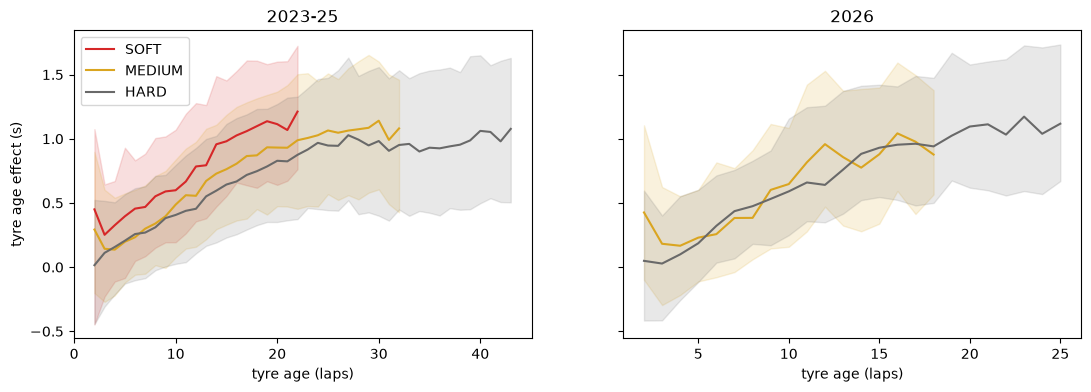

In [11]:
MIN_BIN_LAPS = 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (era, group) in zip(axes, clean.dropna(subset=["age_effect"]).groupby("era")):
    for compound in DRY_COMPOUNDS:
        by_age = group[group["compound"] == compound].groupby("tyre_age")["age_effect"]
        stats = by_age.quantile([0.25, 0.5, 0.75]).unstack()[by_age.size() >= MIN_BIN_LAPS]
        ax.plot(stats.index, stats[0.5], color=COLORS[compound], label=compound)
        ax.fill_between(stats.index, stats[0.25], stats[0.75], color=COLORS[compound], alpha=0.15)
    ax.set(title=era, xlabel="tyre age (laps)")
axes[0].set_ylabel("tyre age effect (s)")
axes[0].legend()
fig.savefig(FIG_DIR / "eda_degradation_shape.png", dpi=120, bbox_inches="tight")

In [12]:
slopes.assign(
    rmse_gain_ms=1000 * (slopes["rmse_linear"] - slopes["rmse_quadratic"]),
    curve_at_max_age_s=slopes["curve"] * slopes["max_age"] ** 2,
).groupby("compound").agg(
    race_compounds=("slope", "size"),
    slope=("slope", "median"),
    curve=("curve", "median"),
    curve_positive=("curve", lambda curve: (curve > 0).mean()),
    curve_at_max_age_s=("curve_at_max_age_s", "median"),
    rmse_gain_ms=("rmse_gain_ms", "median"),
)

,race_compounds,slope,curve,curve_positive,curve_at_max_age_s,rmse_gain_ms
compound,,,,,,
HARD,69,0.039,-7.593e-05,0.478,-0.221,2.598
MEDIUM,69,0.052,6.264e-05,0.522,0.198,6.199
SOFT,37,0.060,8.261e-04,0.622,0.539,5.422


median           size        
stint_ends_in_pit  False  True    False   True 
laps_to_stint_end                              
0.0                0.075    NaN  1084.0     NaN
1.0               -0.001  0.111  1141.0  1944.0
2.0               -0.041  0.029  1135.0  2084.0
3.0               -0.058 -0.008  1126.0  2115.0
4.0               -0.061 -0.020  1128.0  2066.0
5.0               -0.063 -0.030  1126.0  2035.0
6.0               -0.055 -0.023  1135.0  1961.0
7.0               -0.100 -0.038  1110.0  1930.0
8.0               -0.102 -0.063  1113.0  1864.0
9.0               -0.111 -0.058  1077.0  1779.0
10.0              -0.130 -0.071  1064.0  1696.0
11.0              -0.125 -0.077  1059.0  1602.0
12.0              -0.115 -0.064  1068.0  1524.0

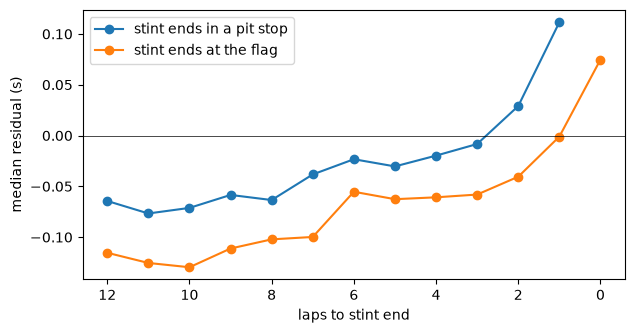

In [13]:
end = clean[clean["laps_to_stint_end"] <= 12].groupby(["stint_ends_in_pit", "laps_to_stint_end"])["residual"].agg(["median", "size"])
fig, ax = plt.subplots(figsize=(7, 3.5))
for ends_in_pit, label in ((True, "stint ends in a pit stop"), (False, "stint ends at the flag")):
    series = end.loc[ends_in_pit, "median"]
    ax.plot(series.index, series.values, marker="o", label=label)
ax.axhline(0, color="black", linewidth=0.5)
ax.invert_xaxis()
ax.set(xlabel="laps to stint end", ylabel="median residual (s)")
ax.legend()
end.unstack("stint_ends_in_pit")

In [14]:
def spread(group):
    per_circuit = group.groupby("circuit")["slope"]
    return {
        "race_compounds": len(group),
        "circuits": per_circuit.ngroups,
        "sd_all": group["slope"].std(),
        "sd_between_circuits": per_circuit.mean().std(),
        "sd_within_circuit": per_circuit.std().median(),
    }


display(pd.DataFrame({compound: spread(group) for compound, group in slopes.groupby("compound")}).T)
slopes.pivot_table(index="circuit", columns="compound", values="slope", aggfunc="median").sort_values("MEDIUM")

,race_compounds,circuits,sd_all,sd_between_circuits,sd_within_circuit
HARD,69.0,26.0,0.031,0.025,0.016
MEDIUM,69.0,26.0,0.038,0.028,0.016
SOFT,37.0,20.0,0.053,0.039,0.027


compound,HARD,MEDIUM,SOFT
circuit,,,
Lusail,0.019,0.010,0.097
Monza,0.040,0.015,NaN
Monaco,0.024,0.017,0.069
Miami,0.025,0.018,0.027
Baku,0.008,0.019,NaN
Miami Gardens,0.017,0.020,0.011
Silverstone,0.039,0.031,0.016
Monte Carlo,0.048,0.036,0.035
Zandvoort,0.035,0.041,0.059


**Findings.**
- Within a race, degradation is linear in tyre age: the quadratic term has a median near 0 for HARD and MEDIUM, a positive sign in only about half of the race-compounds, and cuts RMSE by 3–6 ms.
- The pooled curve looks concave (steep for about 15 laps, then flat). That shape comes from mixing races: high-degradation races have short stints, so high tyre ages only come from low-degradation races. A per-race linear slope does not need a concave form.
- No sharp cliff. Residuals rise about 0.18 s over the last 10 laps of stints that end in a stop (−0.07 → +0.11 s), and about 0.13 s for stints that end at the flag. Teams stop when pace drops, and the stint end is future information, so this cannot be a lap time feature.
- Tyre age 2 (lap 2 of the race on the start tyre) sits above the curve: the field is still bunched.
- Circuit matters. Slope sd between circuits 0.025–0.039 s/lap vs 0.016–0.027 within a circuit across seasons. High: Sakhir, Shanghai, Suzuka, Barcelona (MEDIUM 0.07–0.11). Low: Lusail, Monza, Baku, Miami, Monaco (MEDIUM 0.01–0.02).

## 3. Fuel effect separated from tyre age

In [15]:
display(races.groupby("era")[["fuel_s_per_lap", "age_lap_corr"]].describe().T)
fuel_bias = slopes.assign(fuel_bias=slopes["slope_no_fuel"] - slopes["slope"])
fuel_bias.groupby("compound")[["slope_no_fuel", "slope", "fuel_bias"]].median()

era                   2023-25    2026
fuel_s_per_lap count   61.000  10.000
               mean    -0.056  -0.047
               std      0.018   0.021
               min     -0.099  -0.077
               25%     -0.069  -0.063
               50%     -0.054  -0.050
               75%     -0.044  -0.035
               max     -0.026  -0.011
age_lap_corr   count   61.000  10.000
               mean     0.542   0.550
               std      0.169   0.179
               min     -0.074   0.271
               25%      0.453   0.471
               50%      0.546   0.545
               75%      0.627   0.623
               max      0.916   0.842

,slope_no_fuel,slope,fuel_bias
compound,,,
HARD,-0.007,0.039,-0.051
MEDIUM,-0.006,0.052,-0.056
SOFT,0.005,0.060,-0.050


,season,round,circuit,era,laps,fuel_s_per_lap,age_lap_corr,rmse,rmse_quadratic
20,2024,2,Jeddah,2023-25,769,-0.099,0.792,0.603,0.598
22,2024,4,Suzuka,2023-25,733,-0.094,0.453,0.682,0.655
17,2023,21,Las Vegas,2023-25,602,-0.091,0.560,0.734,0.711
28,2024,11,Spielberg,2023-25,1240,-0.026,0.460,0.456,0.449
65,2026,6,Monte Carlo,2026,1135,-0.024,0.271,1.158,1.125
64,2026,4,Miami Gardens,2026,766,-0.011,0.468,0.629,0.628


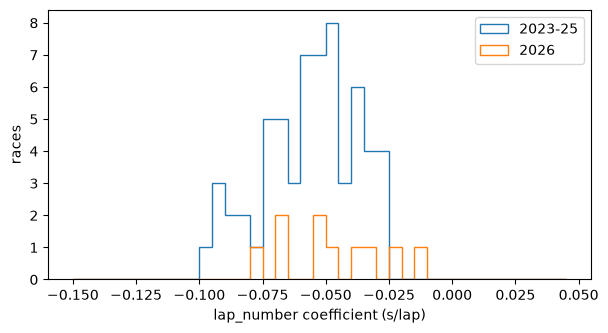

In [16]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for era, group in races.groupby("era"):
    ax.hist(group["fuel_s_per_lap"], bins=np.arange(-0.15, 0.05, 0.005), histtype="step", label=era)
ax.set(xlabel="lap_number coefficient (s/lap)", ylabel="races")
ax.legend()
fig.savefig(FIG_DIR / "eda_fuel_effect.png", dpi=120, bbox_inches="tight")
races.sort_values("fuel_s_per_lap").iloc[[0, 1, 2, -3, -2, -1]]

**Findings.**
- `lap_number` coefficient: median −0.054 s/lap (IQR −0.069 to −0.044) in 2023–25, −0.050 in 2026. It includes track evolution.
- Without the fuel term, compound slopes are about 0 (−0.007 to +0.005 s/lap). Fuel burn hides the degradation almost exactly, so raw slopes cannot be read as degradation.
- Fuel and tyre age separate because the two only correlate at 0.55 within a race (stops at different laps, used tyres).
- Per-lap fuel effect follows lap length: largest at long laps (Jeddah, Suzuka, Las Vegas, about −0.09 to −0.10), smallest at Spielberg (−0.026, shortest lap). 2026 Monaco and Miami are poorly identified (low age–lap correlation, −0.01 to −0.02). A pooled per-km coefficient is safer than a per-race one.

## 4. Track temperature vs degradation

,r_across,per_10c_across,n_within,r_within_circuit,per_10c_within_circuit
HARD,0.107,3.832e-03,67.0,0.514,0.019
MEDIUM,-0.009,-3.639e-04,67.0,0.266,0.012
SOFT,-0.090,-5.556e-03,28.0,0.458,0.031


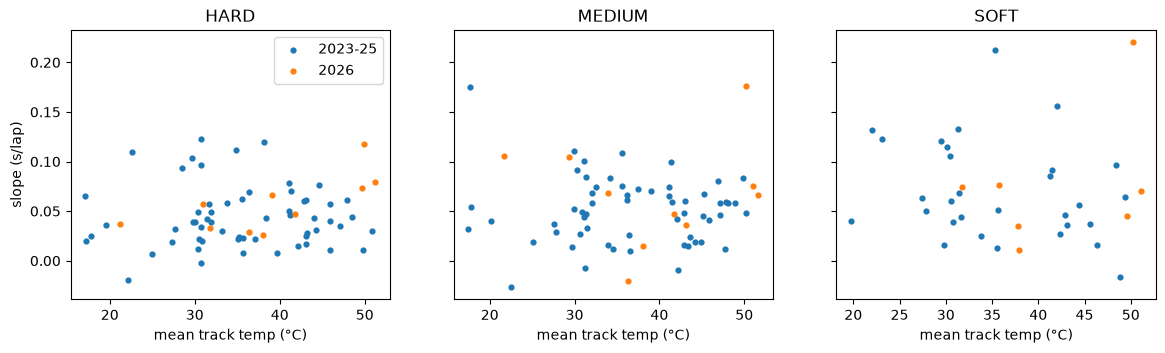

In [17]:
def temperature_effect(group):
    repeated = group[group.groupby("circuit")["slope"].transform("size") >= 2]
    temp = repeated["track_temp"] - repeated.groupby("circuit")["track_temp"].transform("mean")
    slope = repeated["slope"] - repeated.groupby("circuit")["slope"].transform("mean")
    return {
        "r_across": group["track_temp"].corr(group["slope"]),
        "per_10c_across": 10 * np.polyfit(group["track_temp"], group["slope"], 1)[0],
        "n_within": len(repeated),
        "r_within_circuit": temp.corr(slope),
        "per_10c_within_circuit": 10 * np.polyfit(temp, slope, 1)[0],
    }


display(pd.DataFrame({compound: temperature_effect(group) for compound, group in slopes.groupby("compound")}).T)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, (compound, group) in zip(axes, slopes.groupby("compound")):
    for era, part in group.groupby("era"):
        ax.scatter(part["track_temp"], part["slope"], s=12, label=era)
    ax.set(title=compound, xlabel="mean track temp (°C)")
axes[0].set_ylabel("slope (s/lap)")
axes[0].legend()

**Findings.**
- Across circuits, track temperature does not predict the slope (r −0.09 to +0.11): circuit identity dominates.
- Within a circuit, hotter races degrade more: r 0.27–0.51, +0.012 (MEDIUM) to +0.031 (SOFT) s/lap per 10 °C.
- Use track temperature as an adjustment on a circuit's slope, not as a global predictor.

## 5. Driver and team degradation beyond the race model
Per stint (at least 8 clean laps), the slope of the reference-fit residual against tyre age is that driver's degradation relative to the race's compound slope. Split-half check: lap-weighted mean per driver-season (or team-season) over odd rounds vs even rounds.

,units,r_odd_even,sd_unit_mean,sd_stint_slope
driver,87.0,0.154,0.010,0.061
team,41.0,0.153,0.007,0.061


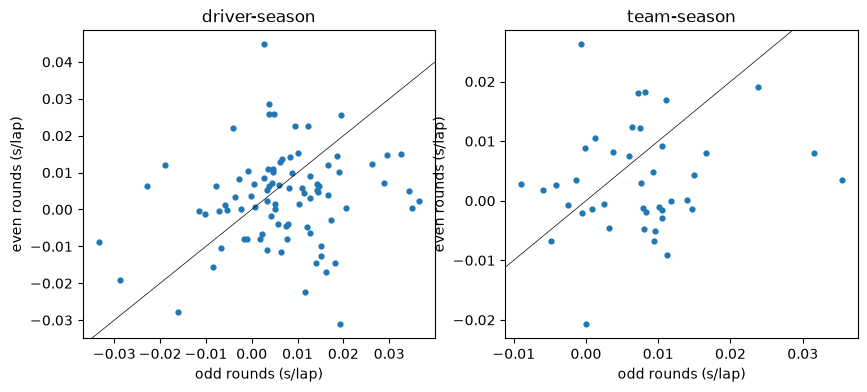

In [18]:
MIN_STINT_LAPS = 8
stint_residual = group_slope(clean, STINT_KEY + ["team", "compound"], "tyre_age", "residual")
stint_residual = stint_residual[stint_residual["laps"] >= MIN_STINT_LAPS].reset_index()
stint_residual["half"] = np.where(stint_residual["round"] % 2 == 1, "odd", "even")


def halves(unit, min_stints=3):
    grouped = stint_residual.assign(weighted=stint_residual["slope"] * stint_residual["laps"]).groupby(["season", unit, "half"])
    means = pd.DataFrame({"slope": grouped["weighted"].sum() / grouped["laps"].sum(), "stints": grouped.size()})
    return means.loc[means["stints"] >= min_stints, "slope"].unstack("half").dropna()


split = {unit: halves(unit) for unit in ("driver", "team")}
display(
    pd.DataFrame(
        {
            unit: {
                "units": len(table),
                "r_odd_even": table["odd"].corr(table["even"]),
                "sd_unit_mean": table.mean(axis=1).std(),
                "sd_stint_slope": stint_residual["slope"].std(),
            }
            for unit, table in split.items()
        }
    ).T
)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (unit, table) in zip(axes, split.items()):
    ax.scatter(table["odd"], table["even"], s=12)
    ax.axline((0, 0), slope=1, color="black", linewidth=0.5)
    ax.set(title=f"{unit}-season", xlabel="odd rounds (s/lap)", ylabel="even rounds (s/lap)")

In [19]:
split["team"].assign(mean=split["team"].mean(axis=1)).sort_values("mean")

half                         even        odd       mean
season team                                            
2026   Mercedes        -2.077e-02 -4.445e-05 -1.041e-02
       Audi            -6.740e-03 -4.876e-03 -5.808e-03
2023   Red Bull Racing  2.828e-03 -8.940e-03 -3.056e-03
2024   RB               1.751e-03 -5.995e-03 -2.122e-03
2026   Racing Bulls    -7.129e-04 -2.459e-03 -1.586e-03
2023   Mercedes        -1.977e-03 -5.831e-04 -1.280e-03
       Aston Martin     2.653e-03 -4.163e-03 -7.551e-04
2024   Ferrari         -4.637e-03  3.185e-03 -7.260e-04
2025   McLaren         -1.359e-03  8.673e-04 -2.460e-04
2024   Mercedes        -5.420e-04  2.516e-03  9.872e-04
2025   Racing Bulls     3.501e-03 -1.400e-03  1.051e-03
2026   Alpine          -9.070e-03  1.127e-02  1.103e-03
2023   AlphaTauri      -6.793e-03  9.481e-03  1.344e-03
2026   McLaren         -4.723e-03  8.044e-03  1.660e-03
2025   Mercedes        -5.089e-03  9.571e-03  2.241e-03
       Aston Martin    -1.833e-03  8.307e-03  3.237e-03
2024   McLaren         -1.157e-03  7.928e-03  3.386e-03
2026   Ferrari         -2.849e-03  1.050e-02  3.827e-03
2023   Ferrari          8.840e-03 -1.728e-04  4.334e-03
2026   Red Bull Racing -1.534e-03  1.054e-02  4.501e-03
       Williams        -1.017e-03  1.010e-02  4.541e-03
2025   Haas F1 Team     2.894e-03  7.669e-03  5.281e-03
2023   Alfa Romeo      -1.037e-04  1.170e-02  5.799e-03
2024   Williams         1.060e-02  1.289e-03  5.946e-03
2023   McLaren          8.194e-03  3.799e-03  5.996e-03
2025   Williams        -1.459e-03  1.467e-02  6.604e-03
2024   Aston Martin     7.423e-03  5.968e-03  6.695e-03
2023   Williams         5.369e-05  1.392e-02  6.985e-03
2025   Ferrari          4.875e-03  9.215e-03  7.045e-03
2024   Kick Sauber      1.235e-02  6.434e-03  9.393e-03
2026   Haas F1 Team     4.397e-03  1.492e-02  9.660e-03
2024   Haas F1 Team     1.222e-02  7.448e-03  9.834e-03
2023   Alpine           9.246e-03  1.049e-02  9.868e-03
2025   Red Bull Racing  8.048e-03  1.661e-02  1.233e-02
       Kick Sauber      1.801e-02  7.207e-03  1.261e-02
2026   Aston Martin     2.622e-02 -6.425e-04  1.279e-02
2024   Alpine           1.831e-02  8.118e-03  1.321e-02
       Red Bull Racing  1.682e-02  1.106e-02  1.394e-02
2023   Haas F1 Team     3.437e-03  3.538e-02  1.941e-02
2026   Cadillac         8.067e-03  3.152e-02  1.979e-02
2025   Alpine           1.903e-02  2.375e-02  2.139e-02

**Findings.**
- Driver and team degradation beyond the race's compound slope barely persists: odd vs even rounds r = 0.15 for both driver-season (87) and team-season (41) units.
- The unit means spread by only 0.007–0.010 s/lap, against a stint slope sd of 0.061 s/lap.
- No driver or team degradation feature in v1. The race reference pace already carries driver pace.

## 6. Practice long-run slopes vs race stint slopes
Both sides are raw slopes of lap time against tyre age (fuel burn included), as `practice_long_runs` stores them. Race stints need at least 5 clean laps, the long-run minimum.

In [20]:
MIN_RUN_LAPS = 5
PAIR_KEY = ["season", "round", "driver", "compound"]


def weighted_mean(frame, keys, value, weight):
    grouped = frame.assign(weighted=frame[value] * frame[weight]).groupby(keys)
    return pd.DataFrame({value: grouped["weighted"].sum() / grouped[weight].sum(), weight: grouped[weight].sum()})


race_stints = group_slope(clean, STINT_KEY + ["compound"], "tyre_age", "lap_time_s")
race_stints = race_stints[race_stints["laps"] >= MIN_RUN_LAPS].reset_index()
race_side = weighted_mean(race_stints, PAIR_KEY, "slope", "laps").rename(columns={"slope": "race_slope", "laps": "race_laps"})
fp_side = weighted_mean(runs, PAIR_KEY, "deg_slope_s_per_lap", "n_laps").rename(columns={"deg_slope_s_per_lap": "fp_slope", "n_laps": "fp_laps"})
paired = race_side.join(fp_side, how="inner").reset_index()
paired["era"] = np.where(paired["season"] == 2026, "2026", "2023-25")
by_race = paired.groupby(["season", "round", "era", "compound"])[["race_slope", "fp_slope"]].mean().reset_index()
by_race["global"] = by_race.groupby(["era", "compound"])["race_slope"].transform("median")


def agreement(frame):
    return {
        "pairs": len(frame),
        "r": frame["fp_slope"].corr(frame["race_slope"]),
        "ols_slope": np.polyfit(frame["fp_slope"], frame["race_slope"], 1)[0],
        "fp_median": frame["fp_slope"].median(),
        "race_median": frame["race_slope"].median(),
    }


display(pd.DataFrame({compound: agreement(group) for compound, group in paired.groupby("compound")}).T.add_prefix("driver_"))
display(pd.DataFrame({compound: agreement(group) for compound, group in by_race.groupby("compound")}).T.add_prefix("race_"))
pd.DataFrame(
    {
        "mae_fp_mean": (by_race["fp_slope"] - by_race["race_slope"]).abs().groupby(by_race["compound"]).mean(),
        "mae_era_median": (by_race["global"] - by_race["race_slope"]).abs().groupby(by_race["compound"]).mean(),
    }
)

,driver_pairs,driver_r,driver_ols_slope,driver_fp_median,driver_race_median
HARD,223.0,0.340,0.146,0.036,0.004
MEDIUM,536.0,0.210,0.113,0.063,0.009
SOFT,147.0,0.152,0.137,0.092,0.042


,race_pairs,race_r,race_ols_slope,race_fp_median,race_race_median
HARD,48.0,0.441,0.183,0.049,0.003
MEDIUM,59.0,0.460,0.237,0.059,0.003
SOFT,28.0,0.254,0.274,0.094,0.029


,mae_fp_mean,mae_era_median
compound,,
HARD,0.101,0.048
MEDIUM,0.096,0.049
SOFT,0.122,0.083


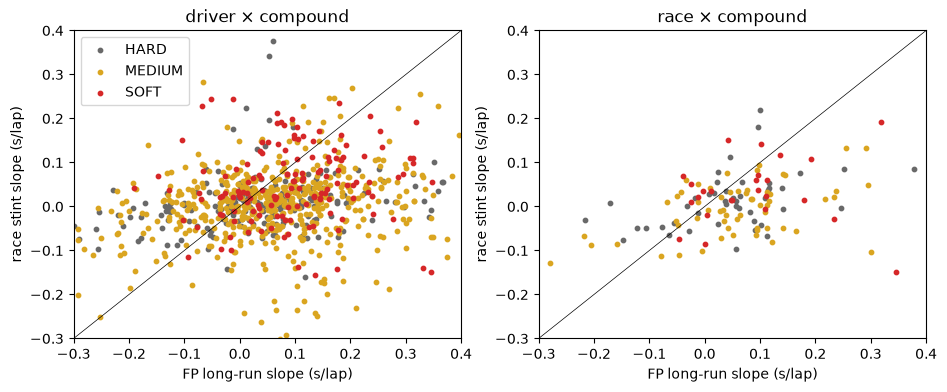

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (title, frame) in zip(axes, (("driver × compound", paired), ("race × compound", by_race))):
    for compound, group in frame.groupby("compound"):
        ax.scatter(group["fp_slope"], group["race_slope"], s=10, color=COLORS[compound], label=compound)
    ax.axline((0, 0), slope=1, color="black", linewidth=0.5)
    ax.set(title=title, xlabel="FP long-run slope (s/lap)", ylabel="race stint slope (s/lap)", xlim=(-0.3, 0.4), ylim=(-0.3, 0.4))
axes[0].legend()
fig.savefig(FIG_DIR / "eda_fp_vs_race_slopes.png", dpi=120, bbox_inches="tight")

**Findings.**
- FP long-run slopes are biased high against race stint slopes on the same raw scale. Medians 0.036 / 0.063 / 0.092 (H/M/S) in FP vs 0.004 / 0.009 / 0.042 in the race.
- Correlation is weak per driver (r 0.15–0.34) and moderate per race × compound (r 0.25–0.46). The regression slope of race on FP is only 0.18–0.27.
- Used as is, the FP mean is worse than the era median per compound (MAE 0.10 vs 0.05 s/lap).
- For model 2, FP is a weak signal: calibrate it (offset and shrinkage) and give it a low weight against the circuit and compound prior. Race laps should take over quickly.

## 7. Traffic effect by gap ahead
Gap to the car ahead at the start of the lap (previous lap's crossing gap), so a slow lap does not create its own large gap. Leaders have no gap and are left out.

median              mean           size      
era        2023-25   2026    2023-25   2026 2023-25  2026
gap                                                      
[0.0, 0.5)   0.294  0.369  3.721e-01  0.483    3580   553
[0.5, 1.0)   0.029  0.038  9.866e-02  0.154   10117  1359
[1.0, 1.5)  -0.012 -0.077  2.206e-02 -0.015    6204   879
[1.5, 2.0)  -0.050 -0.107 -3.464e-04 -0.093    5206   665
[2.0, 3.0)  -0.098 -0.170 -5.984e-02 -0.147    7257   883
[3.0, 5.0)  -0.108 -0.199 -7.756e-02 -0.136    8087  1176
[5.0, inf)  -0.138 -0.129 -9.783e-02 -0.036   13604  3165

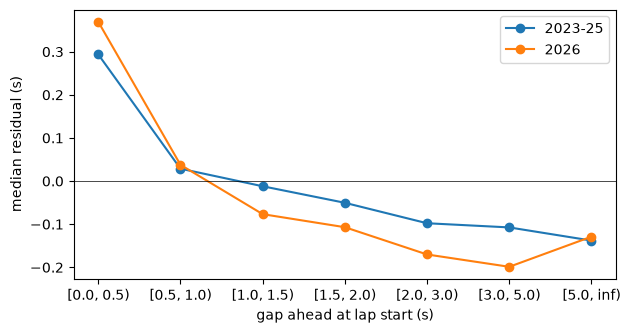

In [22]:
GAP_BINS = [0, 0.5, 1, 1.5, 2, 3, 5, np.inf]
traffic = clean.dropna(subset=["gap_ahead_start_s"]).assign(gap=lambda frame: pd.cut(frame["gap_ahead_start_s"], GAP_BINS, right=False))
table = traffic.groupby(["era", "gap"], observed=True)["residual"].agg(["median", "mean", "size"]).unstack("era")
fig, ax = plt.subplots(figsize=(7, 3.5))
for era in ("2023-25", "2026"):
    ax.plot(table.index.astype(str), table[("median", era)], marker="o", label=era)
ax.axhline(0, color="black", linewidth=0.5)
ax.set(xlabel="gap ahead at lap start (s)", ylabel="median residual (s)")
ax.legend()
fig.savefig(FIG_DIR / "eda_traffic.png", dpi=120, bbox_inches="tight")
table

**Findings.**
- Residual by gap ahead at lap start: +0.29 s (2023–25) / +0.37 s (2026) under 0.5 s, about +0.03 s at 0.5–1 s, and −0.10 to −0.20 s beyond 2 s.
- Against free air (3 s or more), a car within 0.5 s loses about 0.4 (2023–25) to 0.55 s (2026) per lap, one at 0.5–1 s about 0.15–0.2 s, and one at 1–2 s still about 0.1 s in both eras. The loss is larger in 2026, without DRS.
- This is a lower bound: a car that has closed to within 0.5 s is usually the faster one.
- Traffic is worth a feature (gap ahead at lap start, binned or piecewise linear). `in_traffic` at 1.5 s is too coarse.

## 8. Warm-up penalty after the out-lap
The reference fit is refitted without the first 3 laps of every stint after a stop, and those laps are scored against it. `stint_lap` 1 is the first lap after the out-lap.

In [23]:
WARMUP_LAPS = 3
clean["residual_warmup"] = np.nan
for _, race in clean.groupby(["season", "round"]):
    held_out = (race["later_stint"] & (race["stint_lap"] <= WARMUP_LAPS)).to_numpy()
    clean.loc[race.index, "residual_warmup"] = fit(race, train=~held_out)[1]
warmup = clean[clean["later_stint"] & clean["stint_lap"].between(1, 10)]
display(warmup.groupby(["stint_lap", "compound"])["residual_warmup"].median().unstack("compound"))
warmup.groupby(["era", "fresh_tyre", "stint_lap"])["residual_warmup"].median().unstack("stint_lap").iloc[:, :6]

compound,HARD,MEDIUM,SOFT
stint_lap,,,
1.0,-0.161,-0.321,-0.445
2.0,-0.123,-0.238,-0.226
3.0,-0.111,-0.219,-0.162
4.0,-0.078,-0.167,-0.109
5.0,-0.081,-0.144,-0.166
6.0,-0.071,-0.136,-0.205
7.0,-0.074,-0.094,-0.186
8.0,-0.063,-0.096,-0.140
9.0,-0.063,-0.093,-0.147


stint_lap             1.0    2.0    3.0    4.0    5.0    6.0
era     fresh_tyre                                          
2023-25 False      -0.145 -0.105 -0.177 -0.165 -0.182 -0.157
        True       -0.285 -0.164 -0.130 -0.084 -0.082 -0.090
2026    False      -0.240 -0.137  0.296  0.095 -0.308 -0.249
        True       -0.186 -0.210 -0.164 -0.144 -0.124 -0.045

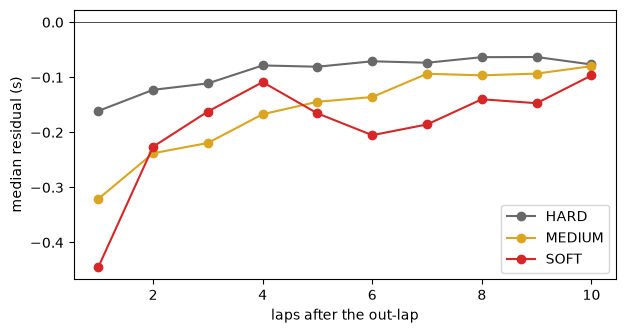

In [24]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for compound, group in warmup.groupby("compound"):
    series = group.groupby("stint_lap")["residual_warmup"].median()
    ax.plot(series.index, series.values, marker="o", color=COLORS[compound], label=compound)
ax.axhline(0, color="black", linewidth=0.5)
ax.set(xlabel="laps after the out-lap", ylabel="median residual (s)")
ax.legend()
fig.savefig(FIG_DIR / "eda_warmup.png", dpi=120, bbox_inches="tight")

**Findings.**
- No warm-up penalty after the out-lap. The first flying lap on new tyres is faster than the linear fit, by about 0.1 (HARD), 0.23 (MEDIUM) and 0.3 s (SOFT) relative to laps 8–10 of the stint. It fades over 3–4 laps.
- On used tyres the first-lap gain is smaller (2023–25: −0.15 vs −0.29 s on fresh).
- The cold tyre penalty (model 5) is all in the out-lap, so estimate it from out-lap times as part of the pit loss, not from the laps after.
- The lap time model needs a fresh-tyre term for the first 2–3 laps of a stint (a linear model under-predicts the undercut).

## 9. 2026 vs 2023–25

count    25%    50%    75%
compound era                                
HARD     2023-25   59.0  0.022  0.039  0.061
         2026      10.0  0.034  0.052  0.072
MEDIUM   2023-25   59.0  0.026  0.049  0.070
         2026      10.0  0.039  0.067  0.097
SOFT     2023-25   30.0  0.037  0.058  0.103
         2026       7.0  0.040  0.070  0.075

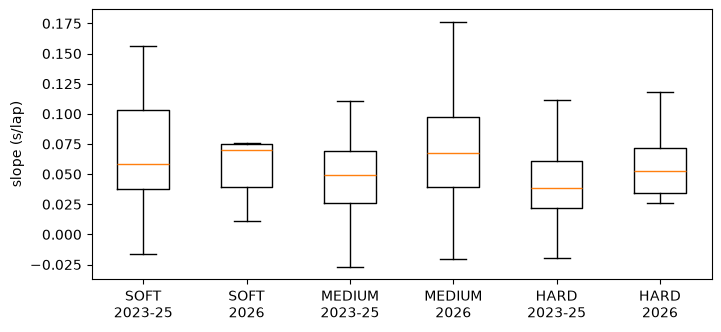

In [25]:
display(slopes.groupby(["compound", "era"])["slope"].describe()[["count", "25%", "50%", "75%"]])
fig, ax = plt.subplots(figsize=(8, 3.5))
groups = [(compound, era) for compound in DRY_COMPOUNDS for era in ("2023-25", "2026")]
ax.boxplot([slopes.loc[(slopes["compound"] == c) & (slopes["era"] == e), "slope"] for c, e in groups], showfliers=False)
ax.set_xticks(range(1, len(groups) + 1), [f"{c}\n{e}" for c, e in groups])
ax.set_ylabel("slope (s/lap)")
fig.savefig(FIG_DIR / "eda_slopes_by_era.png", dpi=120, bbox_inches="tight")

In [26]:
same_circuit = slopes[slopes["season"].isin([2025, 2026])].pivot_table(index=["circuit", "compound"], columns="season", values="slope").dropna()
same_circuit["diff"] = same_circuit[2026] - same_circuit[2025]
display(same_circuit.groupby("compound")["diff"].describe()[["count", "50%", "mean"]])
same_circuit

,count,50%,mean
compound,,,
HARD,5.0,0.021,0.023
MEDIUM,6.0,0.025,0.035
SOFT,3.0,0.086,0.070


season                   2025   2026   diff
circuit       compound                     
Barcelona     MEDIUM    0.059  0.176  0.117
              SOFT      0.096  0.220  0.124
Budapest      HARD      0.042  0.073  0.031
              MEDIUM    0.033  0.066  0.033
              SOFT      0.044  0.045  0.001
Miami Gardens HARD      0.008  0.026  0.018
              MEDIUM    0.025  0.015 -0.010
Shanghai      HARD      0.030  0.037  0.007
              MEDIUM    0.083  0.106  0.022
Spielberg     HARD      0.044  0.080  0.036
              MEDIUM    0.058  0.076  0.017
              SOFT     -0.016  0.070  0.086
Suzuka        HARD      0.036  0.057  0.021
              MEDIUM    0.040  0.069  0.029

**Findings.**
- 2026 degrades faster. Median slopes: HARD 0.052 vs 0.039, MEDIUM 0.067 vs 0.049, SOFT 0.070 vs 0.058 s/lap.
- On the same circuits, 2025 → 2026: median +0.021 (HARD) and +0.025 (MEDIUM) s/lap, Barcelona +0.12.
- Fuel effect is similar (−0.050 vs −0.054 s/lap). Noise is larger (robust sd 0.52 vs 0.48 s).
- With only 10 dry 2026 training races, 2026 slopes need the older circuit history plus an era shift (training variant C).

## 10. Residual noise of the parametric fit

In [27]:
def noise(residual):
    sigma = 1.4826 * (residual - residual.median()).abs().median()
    return {
        "laps": len(residual),
        "sd": residual.std(),
        "robust_sd": sigma,
        "excess_kurtosis": residual.kurt(),
        "q01": residual.quantile(0.01),
        "q05": residual.quantile(0.05),
        "q95": residual.quantile(0.95),
        "q99": residual.quantile(0.99),
        "beyond_3_robust_sd": (residual.abs() > 3 * sigma).mean(),
    }


pd.DataFrame({"all": noise(clean["residual"]), **{era: noise(group["residual"]) for era, group in clean.groupby("era")}}).T

,laps,sd,robust_sd,excess_kurtosis,q01,q05,q95,q99,beyond_3_robust_sd
all,66258.0,0.653,0.480,5.668,-1.420,-0.891,1.124,2.152,0.038
2023-25,57103.0,0.641,0.475,5.820,-1.401,-0.879,1.084,2.097,0.036
2026,9155.0,0.727,0.518,4.726,-1.521,-0.968,1.340,2.396,0.047


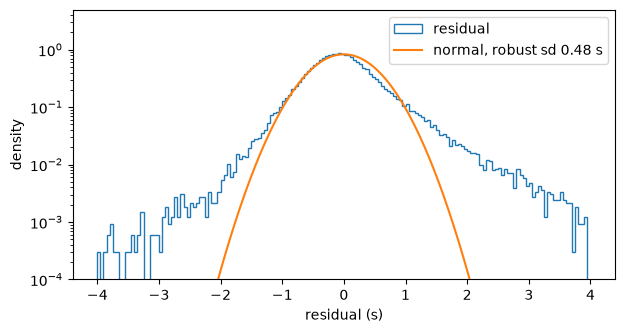

In [28]:
sigma = 1.4826 * (clean["residual"] - clean["residual"].median()).abs().median()
grid = np.linspace(-4, 4, 400)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(clean["residual"], bins=np.arange(-4, 4, 0.05), density=True, histtype="step", label="residual")
ax.plot(grid, np.exp(-0.5 * (grid / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi)), label=f"normal, robust sd {sigma:.2f} s")
ax.set(yscale="log", ylim=(1e-4, None), xlabel="residual (s)", ylabel="density")
ax.legend()
fig.savefig(FIG_DIR / "eda_residuals.png", dpi=120, bbox_inches="tight")

In [29]:
per_driver = clean.groupby(["season", "driver"])["residual"].agg(["std", "size"])
display(per_driver[per_driver["size"] >= 300]["std"].describe().to_frame("driver_season_sd").T)
display(races.loc[~races["circuit"].isin(["Monaco", "Monte Carlo"]), "rmse"].describe().to_frame("race_rmse_without_monaco").T)
races.sort_values("rmse")[["season", "round", "circuit", "laps", "rmse"]].iloc[[0, 1, 2, -3, -2, -1]]

,count,mean,std,min,25%,50%,75%,max
driver_season_sd,82.0,0.65,0.117,0.449,0.552,0.637,0.723,0.928


,count,mean,std,min,25%,50%,75%,max
race_rmse_without_monaco,68.0,0.599,0.106,0.384,0.534,0.586,0.638,0.94


,season,round,circuit,laps,rmse
52,2025,16,Monza,878,0.384
3,2023,4,Baku,784,0.441
28,2024,11,Spielberg,1240,0.456
26,2024,8,Monaco,1151,0.995
65,2026,6,Monte Carlo,1135,1.158
46,2025,8,Monaco,1164,1.423


In [30]:
by_stint_clean = clean.groupby(STINT_KEY)
adjacent = by_stint_clean["lap_number"].diff().eq(1)
stint_demeaned = clean["residual"] - by_stint_clean["residual"].transform("mean")


def lag1(values, mask):
    return values[mask].corr(values.groupby([clean[k] for k in STINT_KEY]).shift()[mask])


pd.DataFrame(
    {
        era: {
            "lag1_residual": lag1(clean["residual"], adjacent & (clean["era"] == era)),
            "lag1_stint_demeaned": lag1(stint_demeaned, adjacent & (clean["era"] == era)),
            "sd_stint_mean": by_stint_clean["residual"].mean()[clean.groupby(STINT_KEY)["era"].first() == era].std(),
        }
        for era in ("2023-25", "2026")
    }
).T

,lag1_residual,lag1_stint_demeaned,sd_stint_mean
2023-25,0.560,0.413,0.403
2026,0.526,0.405,0.447


**Findings.**
- Residual sd 0.65 s, robust sd 0.48 s, excess kurtosis 5.7. The tails are heavy and skewed slow (1% quantile −1.42 s, 99% +2.15 s); 3.8% of laps lie beyond 3 robust sd, against 0.3% for a normal.
- Per driver-season sd 0.45–0.93 s (median 0.64 s). The noisiest races are Monaco (1.0–1.4 s), where lap time follows race management, not tyres.
- Residuals are correlated within a stint: lag-1 autocorrelation 0.56 raw, 0.41 after removing each stint's mean. Stint means have sd 0.40–0.45 s.
- For model 3, iid normal noise understates the uncertainty. Use a per-stint random offset, AR(1) lap-to-lap noise and a heavy-tailed (Student-t or empirical) innovation.

## Recommendation
**Baseline form** (parametric, per race), to beat before any ML:

`lap_delta = compound offset + compound slope × tyre_age + fuel × laps_done + fresh-tyre bonus(stint_lap ≤ 3) + traffic(gap ahead at lap start) + noise`

- Linear tyre age within a race is enough; no quadratic or cliff term.
- Fuel: one pooled coefficient scaled by lap length, about −0.054 s/lap on an average lap.
- Slopes come from a prior: compound × circuit history, a 2026 era shift (about +0.02 s/lap) and a track temperature adjustment within the circuit. The prior is updated with race laps (model 2); FP long runs enter calibrated and with a low weight.
- Noise: stint random offset + AR(1) + heavy-tailed innovation (model 3).

**Is ML justified?** Not as the main lap time model. The parametric form leaves no large structured error: outside Monaco the median per-race RMSE is 0.59 s (0.38–0.94 s), most of it lap-to-lap noise. The hard part is the slope for an unseen race. That is a small hierarchical estimation problem (about 175 race-compound slopes), which suits a Bayesian prior (models 2 and 11) better than a flexible regressor. One ML candidate is worth a grouped-CV comparison against the baseline: gradient-boosted trees on the baseline residual (traffic, stint lap, track temperature, circuit, era). Adopt it only if it beats the baseline on race-grouped folds.

**Key features:** compound, tyre age, laps done (fuel) with lap length, gap ahead at lap start, stint lap ≤ 3, circuit, era (2026), track temperature. Not used: driver or team degradation (not persistent), `laps_to_stint_end` (future information).